In [1]:
import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)


In [3]:
DATA_PATH = r'rd/Final_SDM_Data.csv'   
N_ITER = 100          
PIPELINES = ['corr', 'vif', 'pca']   # which feature-handling pipelines to run
CORR_THRESHOLD = 0.5  # correlation filter threshold (as in corr.ipynb)
TUNE_EACH_ITER = True # True  = run GridSearchCV in every iteration (slow, "entire code")
                      # False = reuse the best params you already found (much faster)

In [4]:
df = pd.read_csv(DATA_PATH)
non_predictors = ['presence', 'koppen_zone', 'decimalLongitude', 'decimalLatitude']
predictor_cols = [c for c in df.columns if c not in non_predictors]
X_all = df[predictor_cols]
y_all = df['presence']

In [5]:
def calculate_vif(data):
    return pd.DataFrame({
        'Feature': data.columns,
        'VIF': [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    })

X_vif = X_all.copy()
while True:
    vif = calculate_vif(X_vif)
    if vif['VIF'].max() < 5:
        break
    X_vif = X_vif.drop(columns=[vif.loc[vif['VIF'].idxmax(), 'Feature']])
vif_features = X_vif.columns.tolist()
print('VIF-selected features:', vif_features)

VIF-selected features: ['dist_in_km_railways', 'dist_in_km_road', 'distance_in_km_urban', 'distance_in_km_lakes', 'dist_in_km_river', 'bio13_precipitation_wettest_month', 'bio14_precipitation_driest_month', 'bio18_precipitation_warmest_quarter', 'bio19_precipitation_coldest_quarter', 'bio4_temperature_seasonality']


In [6]:
def drop_highly_correlated(data, threshold=0.5):
    data = data.copy()
    while True:
        corr = data.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        max_corr = upper.max().max()
        if max_corr < threshold:
            break
        data = data.drop(columns=[upper.max().idxmax()])
    return data

corr_features = drop_highly_correlated(X_all, CORR_THRESHOLD).columns.tolist()
print('Correlation-selected features:', corr_features)

Correlation-selected features: ['dist_in_km_railways', 'dist_in_km_road', 'distance_in_km_urban', 'distance_in_km_lakes', 'bio1_annual_mean_temperature', 'bio12_annual_precipitation', 'bio14_precipitation_driest_month', 'bio18_precipitation_warmest_quarter']


In [7]:
def get_models(seed):
    """Return {name: (estimator, param_grid)}"""
    return {
        'Random Forest': (RandomForestClassifier(random_state=seed),
                          {'n_estimators': [100, 200, 500],
                           'max_depth': [None, 5, 10, 20],
                           'min_samples_split': [2, 5, 10]}),
        'Decision Tree': (DecisionTreeClassifier(random_state=seed),
                          {'max_depth': [3, 5, 10, 20, None],
                           'min_samples_split': [2, 5, 10],
                           'min_samples_leaf': [1, 2, 4]}),
        'KNN': (KNeighborsClassifier(),
                {'n_neighbors': [3, 5, 7, 9, 11],
                 'weights': ['uniform', 'distance'],
                 'metric': ['euclidean', 'manhattan']}),
        'Logistic': (LogisticRegression(max_iter=5000),
                     {'C': [0.01, 0.1, 1, 10, 100]}),
        'XGBoost': (XGBClassifier(random_state=seed, eval_metric='logloss'),
                    {'n_estimators': [100, 200],
                     'max_depth': [3, 5, 7],
                     'learning_rate': [0.01, 0.05, 0.1]}),
        'SVM': (SVC(probability=True, random_state=seed),
                {'C': [0.1, 1, 10, 100],
                 'gamma': ['scale', 0.1, 0.01, 0.001],
                 'kernel': ['rbf', 'linear']}),
    }


FIXED_PARAMS = {
    'corr': {
        'Random Forest': {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500},
        'Decision Tree': {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5},
        'KNN': {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'},
        'Logistic': {'C': 0.1},
        'XGBoost': {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200},
        'SVM': None,
    },
    'vif': {
        'Random Forest': {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500},
        'Decision Tree': {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10},
        'KNN': {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'},
        'Logistic': {'C': 0.1},
        'XGBoost': {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200},
        'SVM': {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'},
    },
    'pca': {
        'Random Forest': {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500},
        'Decision Tree': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10},
        'KNN': {'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'distance'},
        'Logistic': {'C': 10},
        'XGBoost': {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200},
        'SVM': {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'},
    },
}

def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob),
    }

In [8]:
records = []   # one dict per (pipeline, iteration, model)

for i in range(0, N_ITER):
    seed = i   # different split + model seed each iteration, but reproducible
    print(f'\n=== Iteration {i + 1}/{N_ITER} (seed={seed}) ===')

    for pipe in PIPELINES:
        # --- 1. feature set ---
        if pipe == 'corr':
            X = X_all[corr_features]
        elif pipe == 'vif':
            X = X_all[vif_features]
        else:
            X = X_all

        # --- 2. split BEFORE scaling / PCA ---
        X_train, X_test, y_train, y_test = train_test_split(
            X, y_all, test_size=0.3, random_state=seed, stratify=y_all)

        # --- 3. scale (fit on train only) ---
        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        n_comp = np.nan
        if pipe == 'pca':
            pca_full = PCA().fit(X_train_s)
            n_comp = int(np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.90) + 1)
            pca = PCA(n_components=n_comp)
            X_train_f = pca.fit_transform(X_train_s)
            X_test_f = pca.transform(X_test_s)
        else:
            X_train_f, X_test_f = X_train_s, X_test_s

        # --- 4. train + evaluate every model ---
        for name, (est, grid) in get_models(seed).items():
            if TUNE_EACH_ITER or FIXED_PARAMS[pipe][name] is None:
                gs = GridSearchCV(est, grid, cv=5, scoring='roc_auc', n_jobs=-1)
                gs.fit(X_train_f, y_train)
                best, best_params = gs.best_estimator_, gs.best_params_
            else:
                best_params = FIXED_PARAMS[pipe][name]
                best = est.set_params(**best_params).fit(X_train_f, y_train)

            row = {'Pipeline': pipe, 'Iteration': i, 'Seed': seed, 'Model': name,
                   'n_components': n_comp, 'Best_Params': str(best_params)}
            row.update(evaluate(best, X_test_f, y_test))
            records.append(row)
            print(f"  [{pipe}] {name:14s} AUC={row['ROC_AUC']:.4f}  Acc={row['Accuracy']:.4f}")


=== Iteration 1/3 (seed=0) ===
  [corr] Random Forest  AUC=0.9032  Acc=0.8264
  [corr] Decision Tree  AUC=0.8220  Acc=0.7513
  [corr] KNN            AUC=0.8892  Acc=0.8038
  [corr] Logistic       AUC=0.8116  Acc=0.7388
  [corr] XGBoost        AUC=0.8906  Acc=0.8167
  [corr] SVM            AUC=0.8549  Acc=0.7898
  [vif] Random Forest  AUC=0.9008  Acc=0.8240


C:\Users\hibah\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  [vif] Decision Tree  AUC=0.8251  Acc=0.7518
  [vif] KNN            AUC=0.8845  Acc=0.7965
  [vif] Logistic       AUC=0.8074  Acc=0.7379
  [vif] XGBoost        AUC=0.8924  Acc=0.8110
  [vif] SVM            AUC=0.8596  Acc=0.7970
  [pca] Random Forest  AUC=0.8965  Acc=0.8124
  [pca] Decision Tree  AUC=0.8020  Acc=0.7446
  [pca] KNN            AUC=0.8914  Acc=0.8071
  [pca] Logistic       AUC=0.8191  Acc=0.7427
  [pca] XGBoost        AUC=0.8839  Acc=0.7994
  [pca] SVM            AUC=0.8655  Acc=0.8023

=== Iteration 2/3 (seed=1) ===
  [corr] Random Forest  AUC=0.9113  Acc=0.8398
  [corr] Decision Tree  AUC=0.8191  Acc=0.7532
  [corr] KNN            AUC=0.8993  Acc=0.8235
  [corr] Logistic       AUC=0.8178  Acc=0.7451
  [corr] XGBoost        AUC=0.9001  Acc=0.8326
  [corr] SVM            AUC=0.8674  Acc=0.7961
  [vif] Random Forest  AUC=0.9113  Acc=0.8374
  [vif] Decision Tree  AUC=0.8389  Acc=0.7778
  [vif] KNN            AUC=0.9001  Acc=0.8191
  [vif] Logistic       AUC=0.8128  Acc=0.7

In [9]:
results_long = pd.DataFrame(records)
results_long.to_csv('mc_results_long.csv', index=False)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
for pipe in PIPELINES:
    sub = results_long[results_long['Pipeline'] == pipe]
    for m in metrics:
        # one row per iteration, one column per model (e.g. 100 rows of accuracy)
        wide = sub.pivot(index='Iteration', columns='Model', values=m)
        wide.to_csv(f'mc_{pipe}_{m.lower()}.csv')

summary = (results_long.groupby(['Pipeline', 'Model'])[metrics]
           .agg(['mean', 'std']).round(4))
summary.to_csv('mc_summary.csv')
print('\n=== SUMMARY (mean / std across iterations) ===')
print(summary)


=== SUMMARY (mean / std across iterations) ===
                       Accuracy         Precision          Recall          \
                           mean     std      mean     std    mean     std   
Pipeline Model                                                              
corr     Decision Tree   0.7512  0.0022    0.7853  0.0171  0.6921  0.0199   
         KNN             0.8108  0.0110    0.7909  0.0134  0.8451  0.0086   
         Logistic        0.7371  0.0090    0.7187  0.0090  0.7790  0.0078   
         Random Forest   0.8321  0.0069    0.8413  0.0109  0.8188  0.0050   
         SVM             0.7901  0.0058    0.8034  0.0136  0.7684  0.0072   
         XGBoost         0.8232  0.0084    0.8253  0.0144  0.8201  0.0044   
pca      Decision Tree   0.7597  0.0143    0.7669  0.0036  0.7460  0.0386   
         KNN             0.8137  0.0073    0.8014  0.0117  0.8342  0.0111   
         Logistic        0.7447  0.0054    0.7299  0.0063  0.7771  0.0097   
         Random Forest   0.8

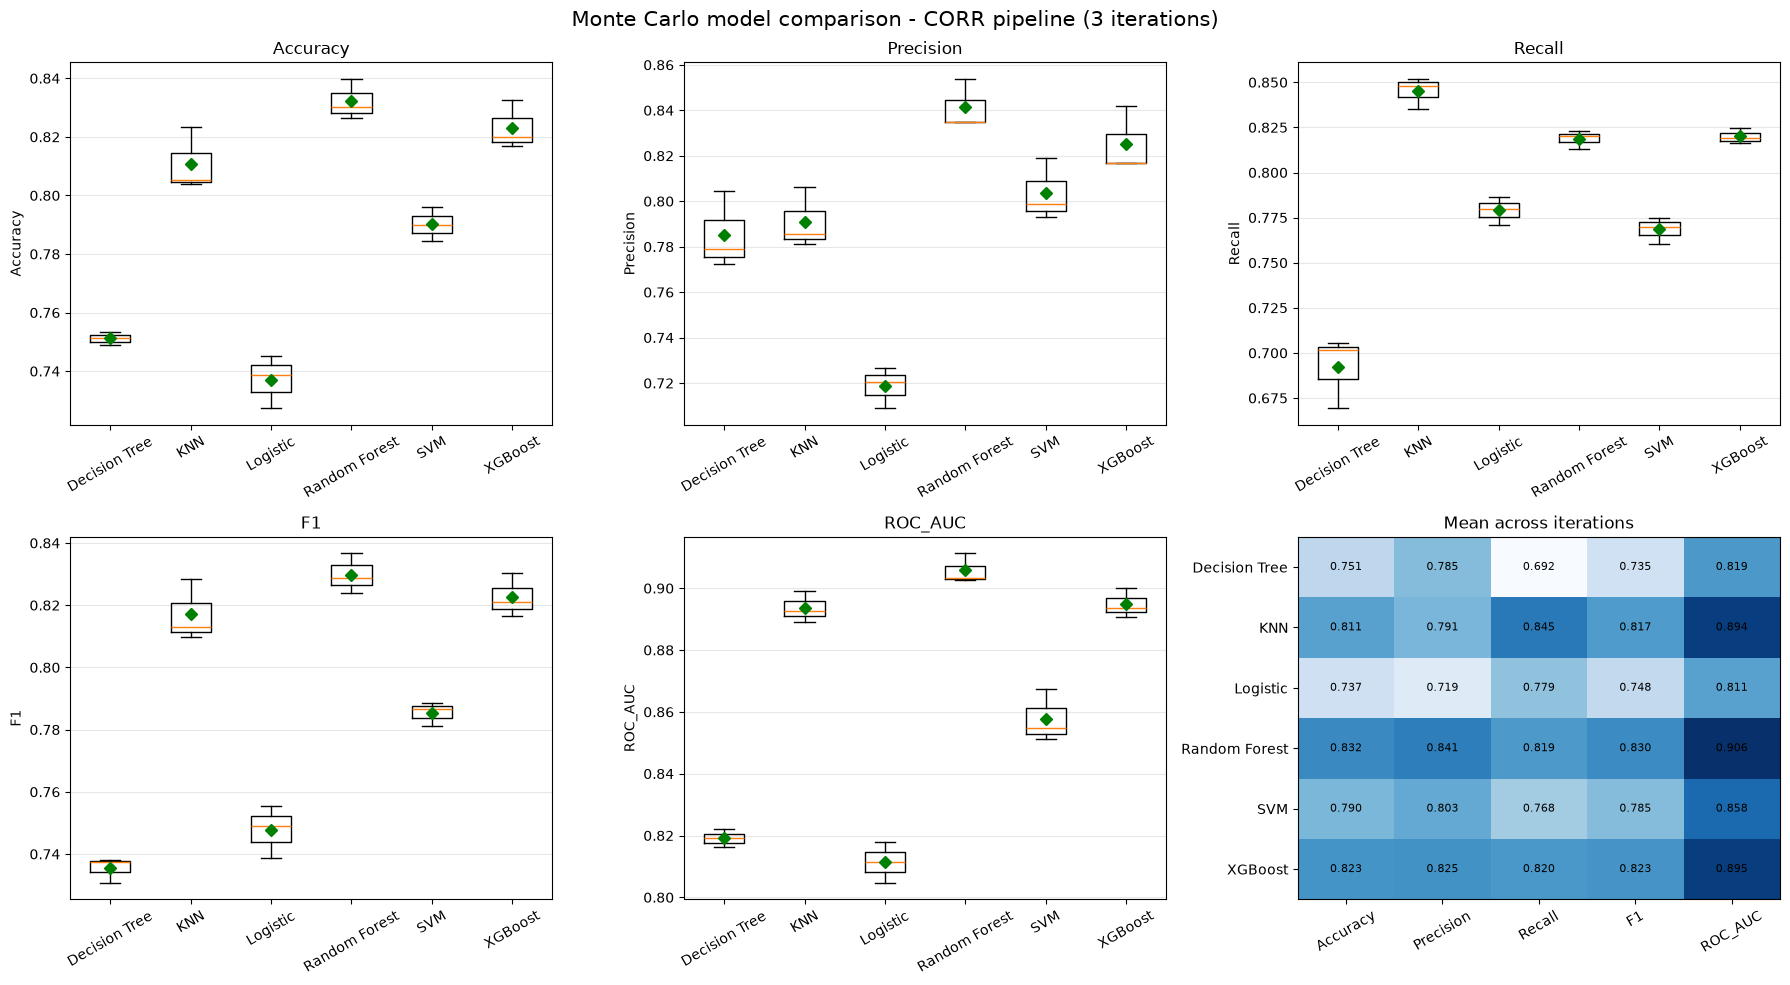

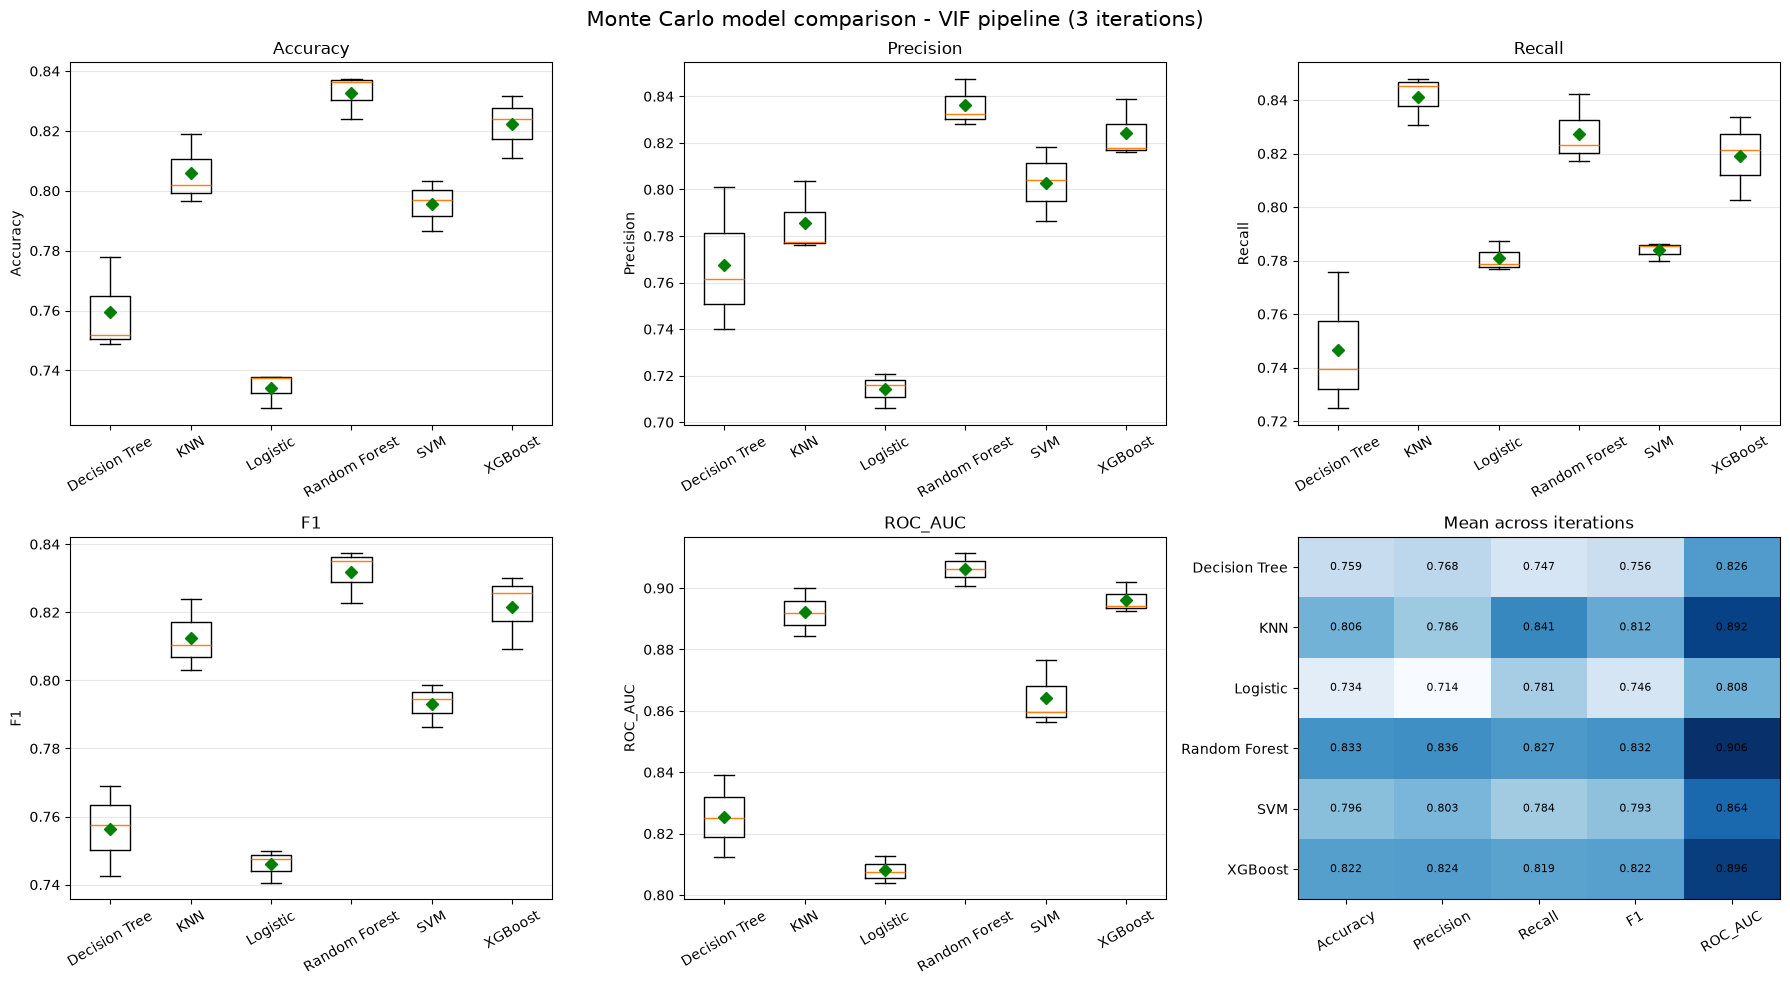

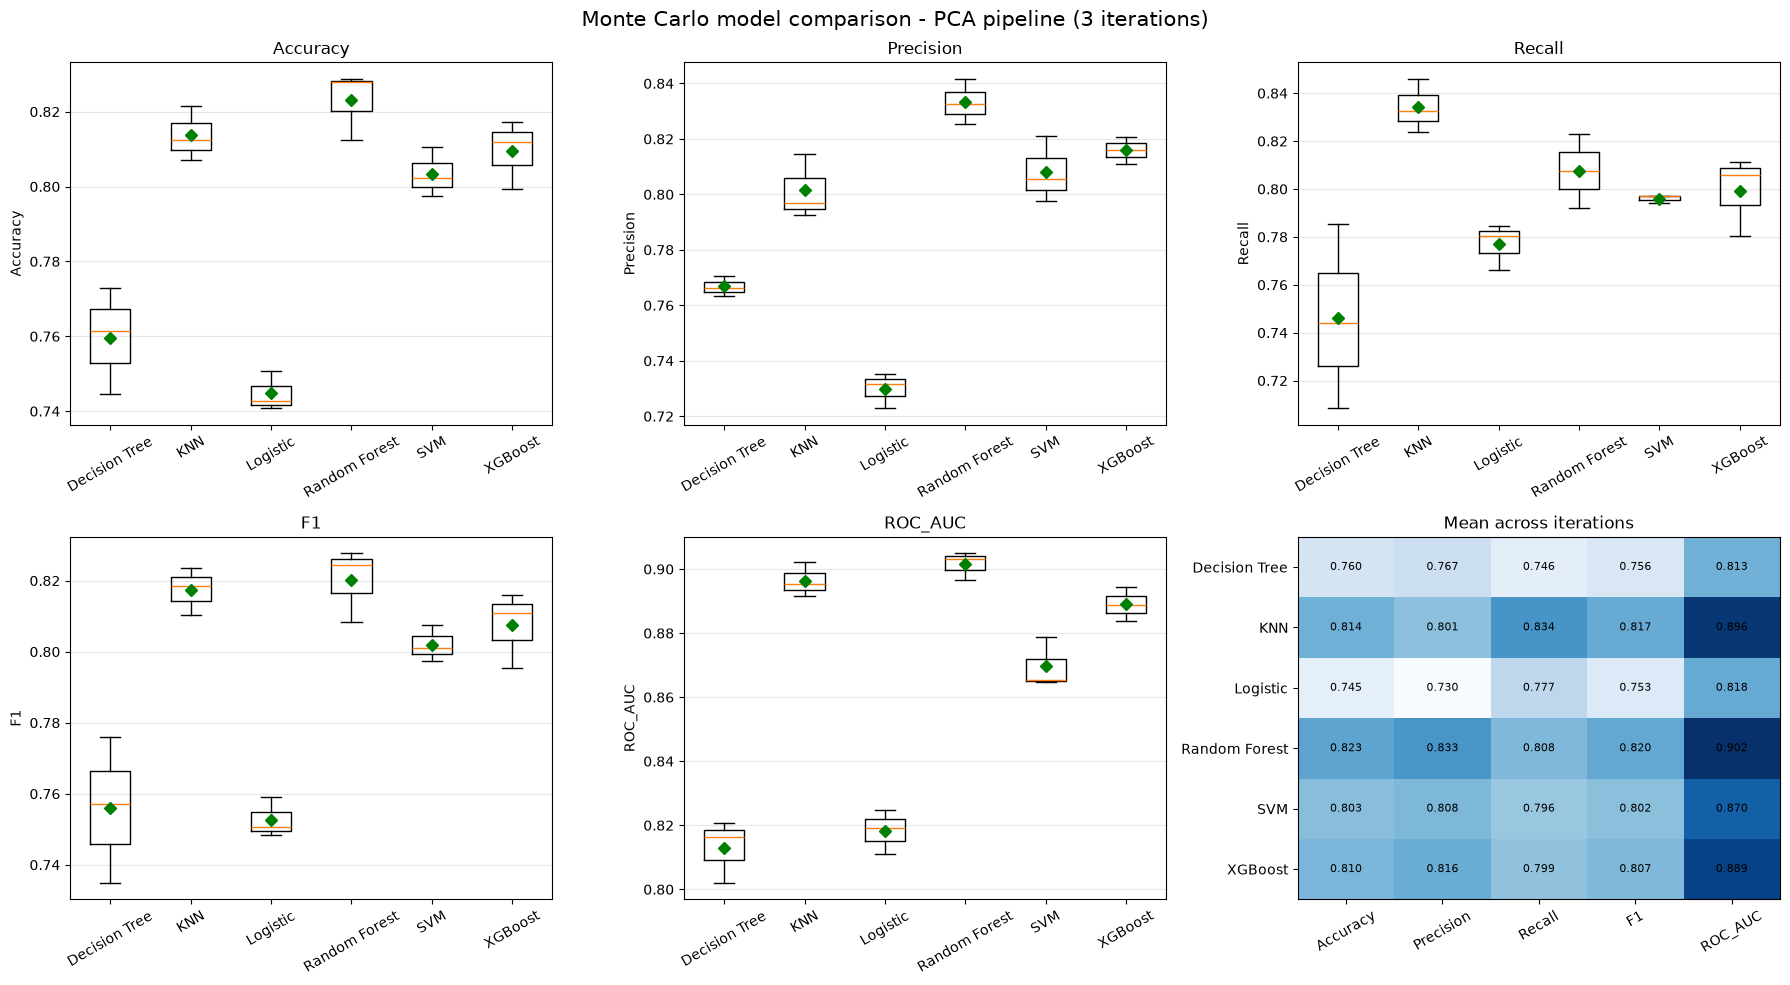

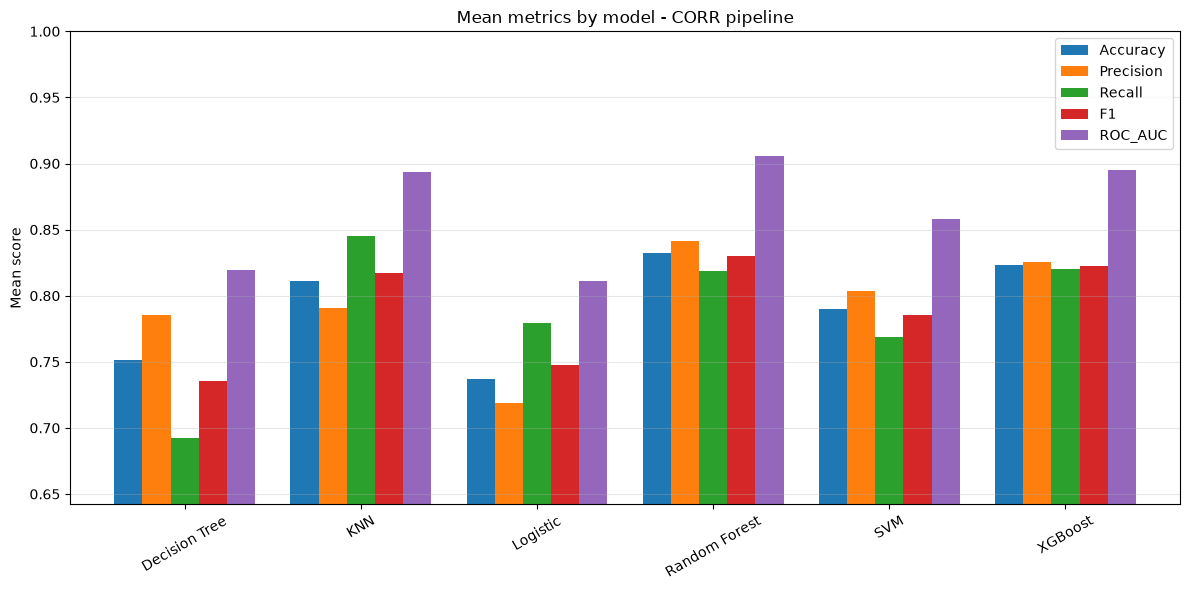

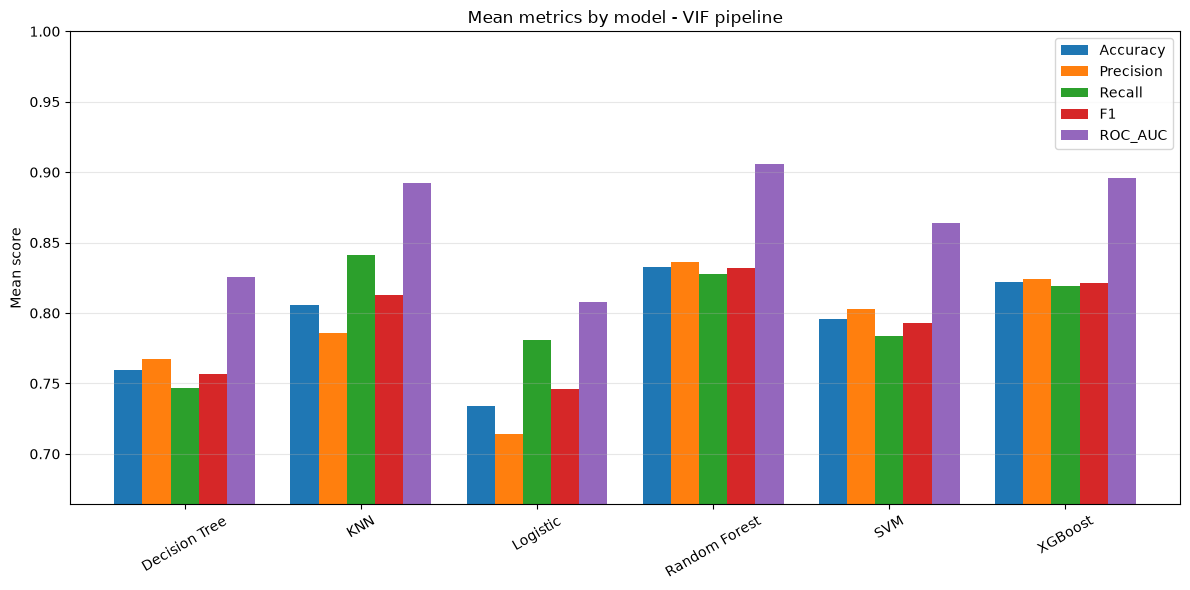

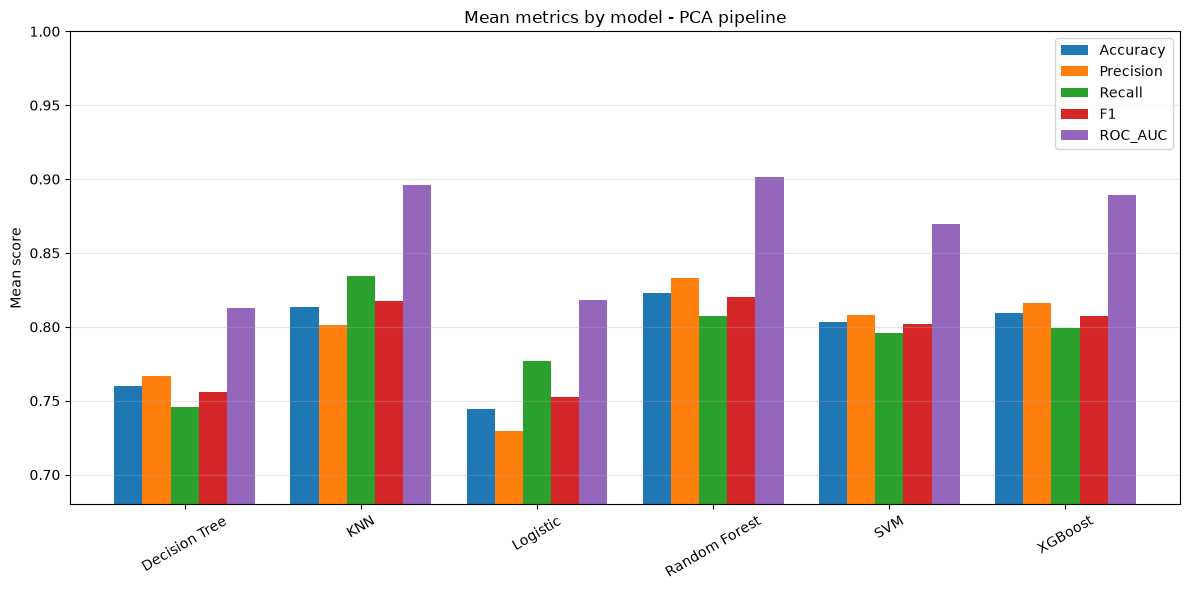

              Pipeline  Accuracy  Precision  Recall      F1  ROC_AUC
Decision Tree     corr    0.7512     0.7853  0.6921  0.7355   0.8191
KNN               corr    0.8108     0.7909  0.8451  0.8171   0.8937
Logistic          corr    0.7371     0.7187  0.7790  0.7476   0.8113
Random Forest     corr    0.8321     0.8413  0.8188  0.8299   0.9057
SVM               corr    0.7901     0.8034  0.7684  0.7855   0.8578
XGBoost           corr    0.8232     0.8253  0.8201  0.8226   0.8948
Decision Tree      vif    0.7595     0.7675  0.7466  0.7564   0.8255
KNN                vif    0.8058     0.7857  0.8412  0.8125   0.8921
Logistic           vif    0.7342     0.7141  0.7809  0.7460   0.8081
Random Forest      vif    0.8326     0.8361  0.8275  0.8317   0.9061
SVM                vif    0.7956     0.8029  0.7838  0.7932   0.8642
XGBoost            vif    0.8222     0.8242  0.8191  0.8216   0.8962
Decision Tree      pca    0.7597     0.7669  0.7460  0.7560   0.8130
KNN                pca    0.8137  

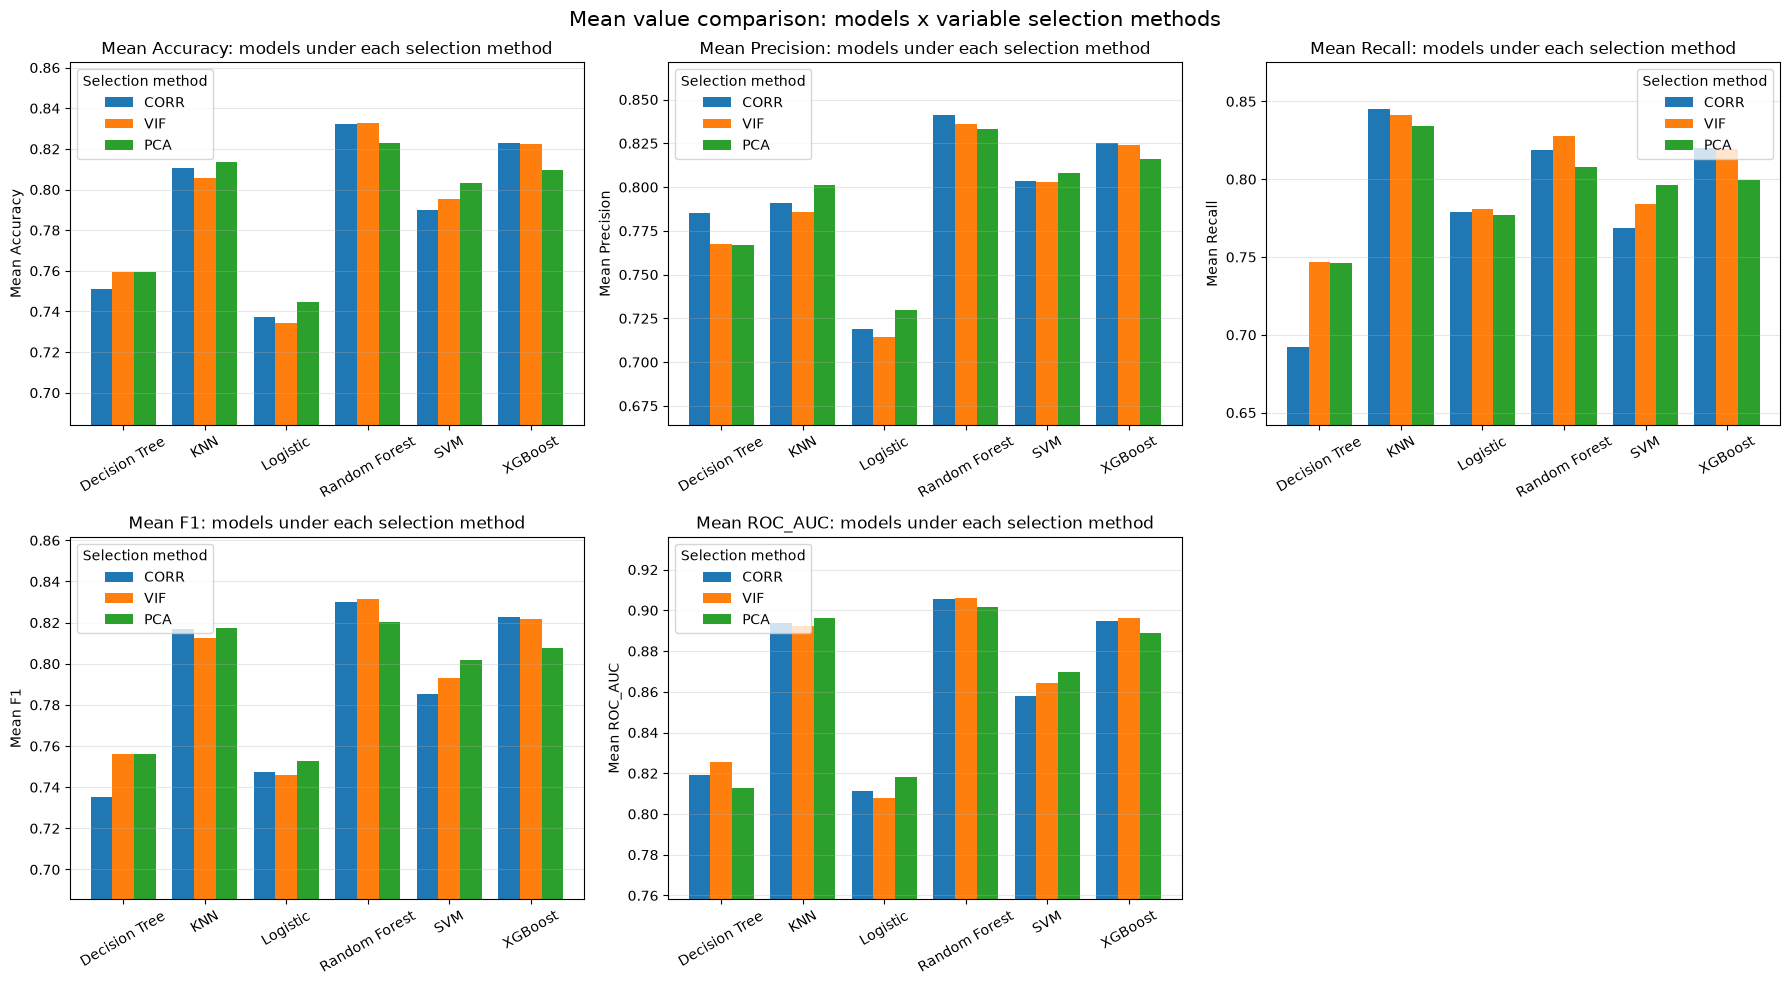

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_DIR = '.'        # folder containing the mc_*.csv files from monte_carlo_sdm.py
OUT_DIR = '.'        # where the PNGs are saved
PIPELINES = ['corr', 'vif', 'pca']
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']

data = {}   # data[pipe][metric] -> DataFrame
for pipe in PIPELINES:
    data[pipe] = {}
    for m in METRICS:
        path = os.path.join(CSV_DIR, f'mc_{pipe}_{m.lower()}.csv')
        if os.path.exists(path):
            data[pipe][m] = pd.read_csv(path, index_col='Iteration')
        else:
            print(f'Missing {path} - skipping')
    if not data[pipe]:
        del data[pipe]

for pipe, metrics_dict in data.items():
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for ax, m in zip(axes, METRICS):
        if m not in metrics_dict:
            ax.axis('off')
            continue
        df_m = metrics_dict[m]
        ax.boxplot([df_m[c].values for c in df_m.columns], showmeans=True,
                   meanprops=dict(marker='D', markerfacecolor='green',
                                  markeredgecolor='green', markersize=6))
        ax.set_xticks(range(1, len(df_m.columns) + 1))
        ax.set_xticklabels(df_m.columns)
        ax.set_title(m)
        ax.set_ylabel(m)
        ax.tick_params(axis='x', rotation=30)
        ax.grid(axis='y', alpha=0.3)

    # 6th panel: mean of every metric, per model (heatmap-style table)
    ax = axes[5]
    means = pd.DataFrame({m: metrics_dict[m].mean() for m in METRICS if m in metrics_dict})
    im = ax.imshow(means.values, aspect='auto', cmap='Blues')
    ax.set_xticks(range(means.shape[1]))
    ax.set_xticklabels(means.columns, rotation=30)
    ax.set_yticks(range(means.shape[0]))
    ax.set_yticklabels(means.index)
    for r in range(means.shape[0]):
        for c in range(means.shape[1]):
            ax.text(c, r, f'{means.values[r, c]:.3f}', ha='center', va='center', fontsize=8)
    ax.set_title('Mean across iterations')

    n_iter = len(next(iter(metrics_dict.values())))
    fig.suptitle(f'Monte Carlo model comparison - {pipe.upper()} pipeline ({n_iter} iterations)',
                 fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'boxplots_{pipe}.png'), dpi=200)
    plt.show()

for pipe, metrics_dict in data.items():
    means = pd.DataFrame({m: metrics_dict[m].mean() for m in METRICS if m in metrics_dict})
    ax = means.plot(kind='bar', figsize=(12, 6), width=0.8)
    ax.set_ylabel('Mean score')
    ax.set_ylim(max(0, means.values.min() - 0.05), 1.0)
    ax.set_title(f'Mean metrics by model - {pipe.upper()} pipeline')
    ax.grid(axis='y', alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'means_{pipe}.png'), dpi=200)
    plt.show()

rows = []
for pipe, metrics_dict in data.items():
    t = pd.DataFrame({m: metrics_dict[m].mean() for m in METRICS if m in metrics_dict})
    t.insert(0, 'Pipeline', pipe)
    rows.append(t)
mean_table = pd.concat(rows).round(4)
mean_table.to_csv(os.path.join(OUT_DIR, 'mc_mean_table.csv'))
print(mean_table)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
for ax, m in zip(axes, METRICS):
    comp = pd.DataFrame({pipe.upper(): d[m].mean() for pipe, d in data.items() if m in d})
    if comp.empty:
        ax.axis('off')
        continue
    comp.plot(kind='bar', ax=ax, width=0.8)
    ax.set_title(f'Mean {m}: models under each selection method')
    ax.set_ylabel(f'Mean {m}')
    ax.set_ylim(max(0, comp.values.min() - 0.05), min(1.0, comp.values.max() + 0.03))
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Selection method')
axes[5].axis('off')
fig.suptitle('Mean value comparison: models x variable selection methods', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'compare_models_by_method.png'), dpi=200)
plt.show()